## Table of Contents

### [1. Linear regression](#linear)
### [2. Decision tree regressor](#dtr)
### [3. Hyperparameters tuning ](#hyp)
    
  *  [3.1 Grid Search](#grid)

  *  [3.2 Random Search](#random)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.tree import plot_tree


In [3]:
df = pd.read_csv('laptop.csv')
df.head()

,Company,TypeName,Ram,OpSys,Weight,Touchscreen,CpuCompany,ClockSpeed,Flash Storage,HDD,Hybrid,SSD,GPU,Ppi,Price
0,Apple,Ultrabook,8,macOS,1.37,0,Intel,2.3,0.000,0.0,0.0,0.128,Intel,312.781955,71378.6832
1,Apple,Ultrabook,8,macOS,1.34,0,Intel,1.8,0.128,0.0,0.0,0.000,Intel,175.939850,47895.5232
2,HP,Notebook,8,No,1.86,0,Intel,2.5,0.000,0.0,0.0,0.256,Intel,192.307692,30636.0000
3,Apple,Ultrabook,16,macOS,1.83,0,Intel,2.7,0.000,0.0,0.0,0.512,AMD,303.896104,135195.3360
4,Apple,Ultrabook,8,macOS,1.37,0,Intel,3.1,0.000,0.0,0.0,0.256,Intel,312.781955,96095.8080


In [4]:
df.shape

(1300, 13)

In [5]:
def evaluation(x_test, y_test,model) :
    
    y_pred = model.predict(x_test)
    mae = metrics.mean_absolute_error(y_test, y_pred)
    msqe = metrics.mean_squared_error(y_test, y_pred)
    r2_score = metrics.r2_score(y_test, y_pred)
    rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
    
    return {'mae':mae,'msqe':msqe,'r2_score':r2_score,'rmse':rmse}

## Linear Regression <a class="anchor" id='linear'></a>

In [7]:
x = df.iloc[:,:-1] #pick up all the rows and column but not the final column
y = df['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)

step1 = ColumnTransformer(
    transformers=[('cat',OneHotEncoder(sparse_output=False,drop='first'),[0,1,2,3,4]),
                 ('num',StandardScaler(),[i for i in range(5,12)])],
    )
step2 = LinearRegression()

pipe = Pipeline([
    ('prepro',step1),
    ('model',step2)
])

pipe.fit(x_train,y_train)

ValueError: could not convert string to float: 'Intel'

In [7]:
ev = pd.DataFrame(evaluation(x_test,y_test,pipe),index=['Linear',]).T
ev

,Linear
mae,0.210721
msqe,0.074495
r2_score,0.800484
rmse,0.272938


## Decision tree regressor  <a class="anchor" id='dtr'></a>

**Algorithm Type:**

It's a supervised learning algorithm used for regression tasks, meaning it's trained on labeled data where the target variable is continuous and not categorical.

**Tree Structure:**

The algorithm constructs a binary tree structure, where each internal node represents a decision based on a feature and a threshold. The leaves of the tree correspond to predicted values for regression tasks.

**Splitting Criteria:** 

Decision tree regressors use various splitting criteria, such as mean squared error (MSE) or mean absolute error (MAE), to determine the best way to partition the data into subsets at each internal node.

**Predictions:** 

To make predictions, the input data traverses the tree from the root to a leaf node, following the decisions made at each node. The predicted value at the leaf node becomes the model's output.

**Overfitting:** 

Decision trees can easily overfit the data by becoming too deep and capturing noise in the training data. Pruning techniques like cost-complexity pruning (ccp_alpha) help mitigate overfitting by controlling the complexity of the tree.

**Advantages:** 

Decision tree regressors are easy to understand and interpret, as they generate human-readable tree structures. They can capture complex relationships between features and the target variable. They're also capable of handling both numerical and categorical features without requiring extensive preprocessing.

**Disadvantages:**

Decision trees are prone to overfitting, especially when they're deep. They might not generalize well to unseen data if they capture noise from the training data. Ensemble techniques like Random Forests and Gradient Boosting are often used to improve their performance.

**Hyperparameter Tuning:**

Hyperparameters like max_depth, min_samples_split, min_samples_leaf, and others control the growth and pruning of the tree. Tuning these hyperparameters is crucial to achieve better model performance and prevent overfitting.

In [8]:
x = df.iloc[:,:-1]
y = df['Price']
y = pd.DataFrame(y)
# y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)

step1 = ColumnTransformer(
    transformers=[('cat',OneHotEncoder(sparse=False,drop='first'),[0,1,2,3,4]),
#                  ('num',StandardScaler(),[i for i in range(5,12)])
                 ],remainder='passthrough',
    )
step2 = DecisionTreeRegressor(random_state=0)

pipe = Pipeline([
    ('prepro',step1),
    ('model',step2)
])

pipe.fit(x_train,y_train)

Pipeline(steps=[('prepro',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse=False),
                                                  [0, 1, 2, 3, 4])])),
                ('model', DecisionTreeRegressor(random_state=0))])

In [9]:
a = evaluation(x_test,y_test,pipe)
ev['DTR'] = [*a.values()]
ev['DTR'] = ev['DTR'].apply(lambda x: '{:.2f}'.format(x))

ev

,Linear,DTR
mae,0.210721,10358.12
msqe,0.074495,336929787.45
r2_score,0.800484,0.72
rmse,0.272938,18355.65


In [10]:
x = df.iloc[:,:-1]
y = df['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)

step1 = ColumnTransformer(
    transformers=[('cat',OneHotEncoder(sparse=False,drop='first'),[0,1,2,3,4]),

#                  ('num',StandardScaler(),[i for i in range(5,12)])
                 ],remainder='passthrough',
    )
step2 = DecisionTreeRegressor(random_state=0)

pipe = Pipeline([
    ('prepro',step1),
    ('model',step2)
])

pipe.fit(x_train,y_train)

Pipeline(steps=[('prepro',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse=False),
                                                  [0, 1, 2, 3, 4])])),
                ('model', DecisionTreeRegressor(random_state=0))])

In [11]:
a = evaluation(x_test,y_test,pipe)
ev['DTR+log'] = [*a.values()]
# ev['DTR+log'] = ev['DTR+log'].apply(lambda x: '{:.2f}'.format(x))

ev

,Linear,DTR,DTR+log
mae,0.210721,10358.12,0.175077
msqe,0.074495,336929787.45,0.061939
r2_score,0.800484,0.72,0.834112
rmse,0.272938,18355.65,0.248876


In [12]:
x = df.iloc[:,:-1]
y = df['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)

step1 = ColumnTransformer(
    transformers=[('cat',OneHotEncoder(sparse=False,drop='first'),[0,1,2,3,4]),

                 ('num',StandardScaler(),[i for i in range(5,12)])
                 ],remainder='passthrough',
    )
step2 = DecisionTreeRegressor(random_state=0)

pipe = Pipeline([
    ('prepro',step1),
    ('model',step2)
])

pipe.fit(x_train,y_train)

Pipeline(steps=[('prepro',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse=False),
                                                  [0, 1, 2, 3, 4]),
                                                 ('num', StandardScaler(),
                                                  [5, 6, 7, 8, 9, 10, 11])])),
                ('model', DecisionTreeRegressor(random_state=0))])

In [13]:
a = evaluation(x_test,y_test,pipe)
ev['DTR+log+std'] = [*a.values()]
# ev['DTR+log'] = ev['DTR+log'].apply(lambda x: '{:.2f}'.format(x))

ev

,Linear,DTR,DTR+log,DTR+log+std
mae,0.210721,10358.12,0.175077,0.175851
msqe,0.074495,336929787.45,0.061939,0.062244
r2_score,0.800484,0.72,0.834112,0.833295
rmse,0.272938,18355.65,0.248876,0.249488


**why scaling is decrease the model performence ?**

Decision trees and ensemble methods do not require feature scaling to be performed as they are not sensitive to the the variance in the data.


## Hyperparameters Tuning <a class ="anchor" id="hyp" ></a>

**Max Depth (max_depth):**

This parameter controls the maximum depth of the tree. Increasing the depth can lead to a more complex model that might overfit the training data. Try different values and use techniques like cross-validation to find the optimal depth.

**Min Samples Split (min_samples_split):**

The minimum number of samples required to split an internal node. Increasing this value can prevent the tree from splitting nodes with a small number of samples, reducing overfitting.

**Min Samples Leaf (min_samples_leaf):**


The minimum number of samples required to be at a leaf node. Similar to min_samples_split, this parameter can help control overfitting by ensuring that each leaf has a minimum amount of data.

**Max Features (max_features):**

The maximum number of features to consider when looking for the best split. You can try different values, such as 'auto' (default), 'sqrt', 'log2', or an integer value.

**Criterion (criterion):**

The function to measure the quality of a split. The default is 'mse' (mean squared error), but you can also try 'friedman_mse' or 'mae' (mean absolute error).

**Min Weight Fraction Leaf (min_weight_fraction_leaf):**

Similar to min_samples_leaf, but expressed as a fraction of the total weight of the data.

**Max Leaf Nodes (max_leaf_nodes):**

The maximum number of leaf nodes. You can use this to limit the growth of the tree.

**Min Impurity Decrease (min_impurity_decrease):**

A node will be split if this split induces a decrease of the impurity greater than or equal to this value. This can be used to control the tree's growth.

**ccp_alpha**

When the ccp_alpha parameter is set to a non-zero value, the algorithm prunes the tree based on a complexity parameter that balances the reduction in impurity (gain in purity) with the number of leaves. Larger values of ccp_alpha result in more aggressive pruning, which can lead to simpler and less overfit trees.

#### GridSearch <a class = "anchor" id = "grid"></a>

In [14]:
df_enc = pd.DataFrame()

for col in df.columns:
    
    if col in df.select_dtypes(include=[np.object_]).columns:
        
        dum = pd.get_dummies(df[col],drop_first=True)
        df_enc = pd.concat([df_enc,dum],axis=1)
    else:
        df_enc[col] = df[col]


In [15]:

x = df_enc.iloc[:,:-1]
y = df_enc['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)



# Create a DecisionTreeRegressor
model = DecisionTreeRegressor(random_state=0)

# Define the parameter grid to search
param_grid = {
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
    
}

# Create the GridSearchCV object
grid_search = GridSearchCV(model, param_grid, cv=3, scoring='neg_mean_squared_error')

# Fit the grid search to your data
grid_search.fit(x_train, y_train)

# Get the best parameters and best estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

print("Best Parameters:", best_params)
print("Best Estimator:", best_estimator)

Best Parameters: {'max_depth': 10, 'max_features': 'auto', 'min_samples_leaf': 4, 'min_samples_split': 10}
Best Estimator: DecisionTreeRegressor(max_depth=10, max_features='auto', min_samples_leaf=4,
                      min_samples_split=10, random_state=0)


In [16]:
a = evaluation(x_test,y_test,best_estimator)
ev['DTR+log+grid'] = [*a.values()]
ev

,Linear,DTR,DTR+log,DTR+log+std,DTR+log+grid
mae,0.210721,10358.12,0.175077,0.175851,0.173551
msqe,0.074495,336929787.45,0.061939,0.062244,0.052391
r2_score,0.800484,0.72,0.834112,0.833295,0.859684
rmse,0.272938,18355.65,0.248876,0.249488,0.228891


#### RandomSearch <a class = "anchor" id = "random"></a>

In [17]:

x = df_enc.iloc[:,:-1]
y = df_enc['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)



# Create a DecisionTreeRegressor
model = DecisionTreeRegressor(random_state=0)

param_grid = {
    'max_depth': [ 6,7,8,9,10,11,12,13,14],
    'min_samples_split': [8,9,10,11,12,13,14,15],
    'min_samples_leaf': [3,4,5],
    'ccp_alpha': [0.0, 0.01, 0.1, 0.5, 1.0]

}

random_search = RandomizedSearchCV(model, param_grid, cv=3, scoring='neg_mean_squared_error')

random_search.fit(x_train, y_train)

# Get the best parameters and best estimator
best_params = random_search.best_params_
best_estimator = random_search.best_estimator_

print("Best Parameters:", best_params)
print("Best Estimator:", best_estimator)

Best Parameters: {'min_samples_split': 8, 'min_samples_leaf': 4, 'max_depth': 11, 'ccp_alpha': 0.0}
Best Estimator: DecisionTreeRegressor(max_depth=11, min_samples_leaf=4, min_samples_split=8,
                      random_state=0)


In [18]:
a = evaluation(x_test,y_test,best_estimator)
ev['DTR+log+random'] = [*a.values()]
ev

,Linear,DTR,DTR+log,DTR+log+std,DTR+log+grid,DTR+log+random
mae,0.210721,10358.12,0.175077,0.175851,0.173551,0.174214
msqe,0.074495,336929787.45,0.061939,0.062244,0.052391,0.053949
r2_score,0.800484,0.72,0.834112,0.833295,0.859684,0.855512
rmse,0.272938,18355.65,0.248876,0.249488,0.228891,0.232269


the Decision tree regressor model for this dataset :

* encoding -> One hot
* transform -> log
* tuning parameters ->  'min_samples_split': 14, 'min_samples_leaf': 4, 'max_depth': 12


In [19]:
x = df_enc.iloc[:,:-1]
y = df_enc['Price']
y = pd.DataFrame(y)
y = np.log(y)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.15,random_state=5)



# Create a DecisionTreeRegressor
best = DecisionTreeRegressor(random_state=0,min_samples_split= 14, min_samples_leaf= 4, max_depth= 12)
best.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=12, min_samples_leaf=4, min_samples_split=14,
                      random_state=0)

In [20]:
a = evaluation(x_test,y_test,best)
ev['best -> DTR'] = [*a.values()]
ev

,Linear,DTR,DTR+log,DTR+log+std,DTR+log+grid,DTR+log+random,best -> DTR
mae,0.210721,10358.12,0.175077,0.175851,0.173551,0.174214,0.172320
msqe,0.074495,336929787.45,0.061939,0.062244,0.052391,0.053949,0.051874
r2_score,0.800484,0.72,0.834112,0.833295,0.859684,0.855512,0.861069
rmse,0.272938,18355.65,0.248876,0.249488,0.228891,0.232269,0.227758


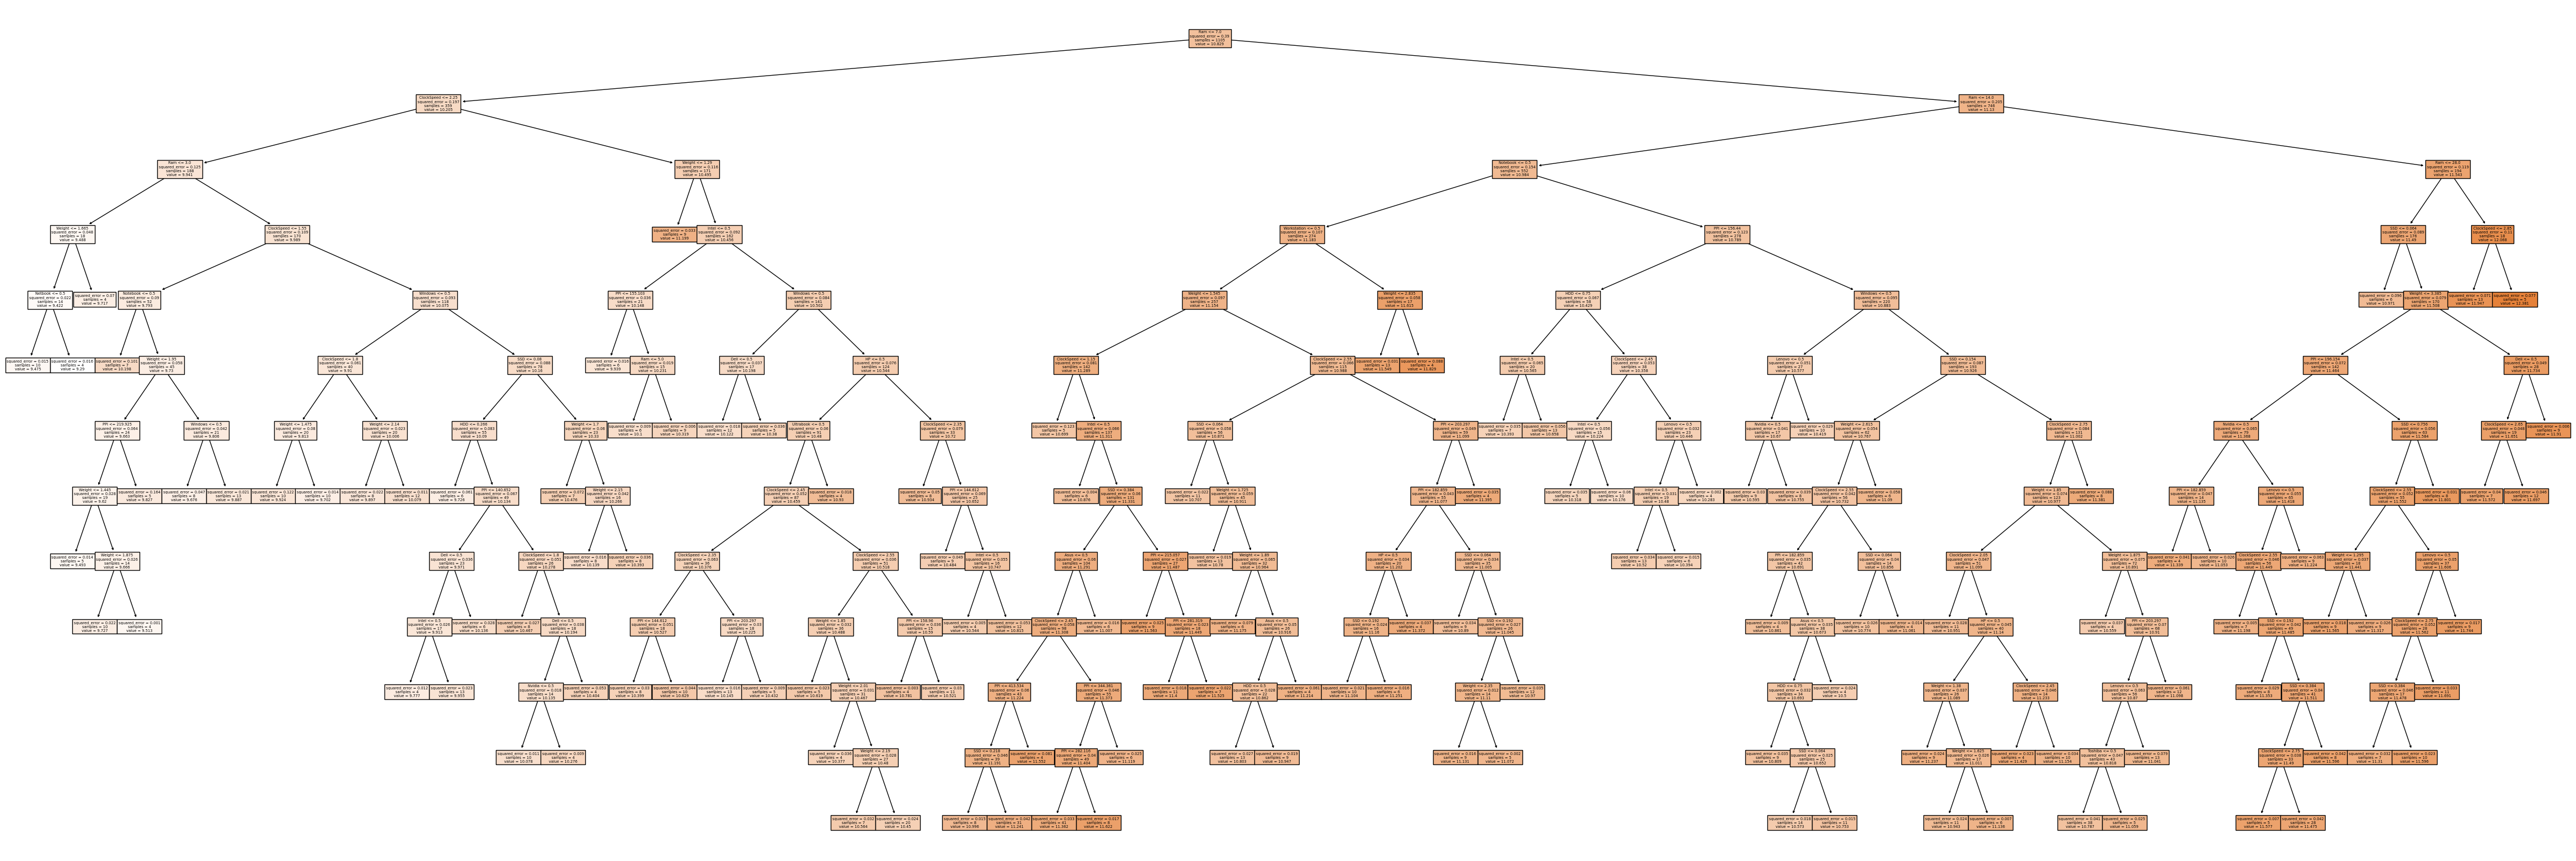

In [21]:
plt.figure(figsize=(60,20))
plot_tree(best,filled=True,feature_names=x.columns)
plt.show()